In [1]:
#import libraries
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

#load dataset
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [2]:
df_india = df[df['job_country'] == 'India'].copy()

In [3]:
df_india['job_posted_month'] = df_india['job_posted_date'].dt.strftime('%B')

In [4]:
df_india.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
16,Data Engineer,Big Data Engineer,"Pune, Maharashtra, India",via LinkedIn,Full-time,False,India,2023-06-15 13:28:03,False,False,India,NaN,NaN,NaN,Hexaware Technologies,"['powershell', 'python', 'sql', 'mysql', 'sql ...","{'cloud': ['databricks', 'azure'], 'databases'...",June
19,Data Scientist,Data Scientist,"Pune, Maharashtra, India",via Indeed,Full-time,False,India,2023-04-26 13:20:12,False,False,India,NaN,NaN,NaN,Bitwise Solutions,"['r', 'sql', 'python', 'scala', 'java', 'c++',...","{'analyst_tools': ['tableau'], 'libraries': ['...",April
29,Data Scientist,Data Scientist,"Pune, Maharashtra, India",via Exusia,Full-time,False,India,2023-03-26 13:16:20,False,False,India,NaN,NaN,NaN,Exusia,NaN,NaN,March
38,Data Analyst,Data Quality and Governance Analyst 1,India,via Trabajo.org,Full-time,False,India,2023-07-23 13:24:57,False,False,India,NaN,NaN,NaN,"Jones Lang LaSalle IP, Inc","['sql', 'python', 'databricks', 'power bi', 'e...","{'analyst_tools': ['power bi', 'excel', 'word'...",July
42,Senior Data Engineer,"Senior Data Engineer(Python)-1563,1637&1633","Chennai, Tamil Nadu, India",via HR Software For Growing Businesses | Fresh...,Full-time,False,India,2023-11-10 13:30:41,True,False,India,NaN,NaN,NaN,CESIT,"['python', 'sql', 'aws', 'pyspark', 'docker', ...","{'async': ['jira'], 'cloud': ['aws'], 'librari...",November


In [5]:
df_india_pivot = df_india.pivot_table(
    index='job_posted_month',
    columns='job_title_short',
    aggfunc='size'
)

df_india_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
April,170,32,418,1566,946,54,86,375,194,169
August,189,25,618,1407,1157,47,126,343,235,148
December,186,27,648,1464,1206,94,77,343,200,133
February,143,35,433,1631,932,42,94,313,165,157
January,175,31,628,2132,1444,70,127,448,269,192
July,142,25,457,1528,1123,54,75,359,204,155
June,146,26,367,1632,1129,41,66,427,238,125
March,116,37,422,1591,1005,34,96,351,194,180
May,103,14,278,1384,837,31,59,329,134,98


In [6]:
df_india_pivot.reset_index(inplace=True)

In [7]:
df_india_pivot

job_title_short,job_posted_month,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
0,April,170,32,418,1566,946,54,86,375,194,169
1,August,189,25,618,1407,1157,47,126,343,235,148
2,December,186,27,648,1464,1206,94,77,343,200,133
3,February,143,35,433,1631,932,42,94,313,165,157
4,January,175,31,628,2132,1444,70,127,448,269,192
5,July,142,25,457,1528,1123,54,75,359,204,155
6,June,146,26,367,1632,1129,41,66,427,238,125
7,March,116,37,422,1591,1005,34,96,351,194,180
8,May,103,14,278,1384,837,31,59,329,134,98
9,November,192,29,722,1743,1614,52,125,423,278,139


In [8]:
df_india_pivot['month'] = pd.to_datetime(df_india_pivot['job_posted_month'], format='%B').dt.month

In [9]:
df_india_pivot.sort_values('month', inplace=True)

In [10]:
df_india_pivot.set_index('job_posted_month', inplace=True)

In [11]:
df_india_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer,month
job_posted_month,,,,,,,,,,,
January,175,31,628,2132,1444,70,127,448,269,192,1
February,143,35,433,1631,932,42,94,313,165,157,2
March,116,37,422,1591,1005,34,96,351,194,180,3
April,170,32,418,1566,946,54,86,375,194,169,4
May,103,14,278,1384,837,31,59,329,134,98,5
June,146,26,367,1632,1129,41,66,427,238,125,6
July,142,25,457,1528,1123,54,75,359,204,155,7
August,189,25,618,1407,1157,47,126,343,235,148,8
September,155,34,630,1508,984,67,85,324,195,132,9


In [12]:
df_india_pivot.drop(columns='month', inplace=True)

In [13]:
df_india_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,175,31,628,2132,1444,70,127,448,269,192
February,143,35,433,1631,932,42,94,313,165,157
March,116,37,422,1591,1005,34,96,351,194,180
April,170,32,418,1566,946,54,86,375,194,169
May,103,14,278,1384,837,31,59,329,134,98
June,146,26,367,1632,1129,41,66,427,238,125
July,142,25,457,1528,1123,54,75,359,204,155
August,189,25,618,1407,1157,47,126,343,235,148
September,155,34,630,1508,984,67,85,324,195,132


In [14]:
specific_jobs = ['Data Analyst', 'Senior Data Analyst', 'Software Engineer']

In [ ]:
top_3_jobs = df_india_pivot.sum().nlargest(3).index

#sum() does a column wise sum of all the values | nlargest(3) takes the top 3 values | index returns just the names of the columns w/o values
top_3_jobs

Index(['Data Engineer', 'Data Scientist', 'Data Analyst'], dtype='str', name='job_title_short')

In [18]:
df_top_3 = df_india_pivot[top_3_jobs]

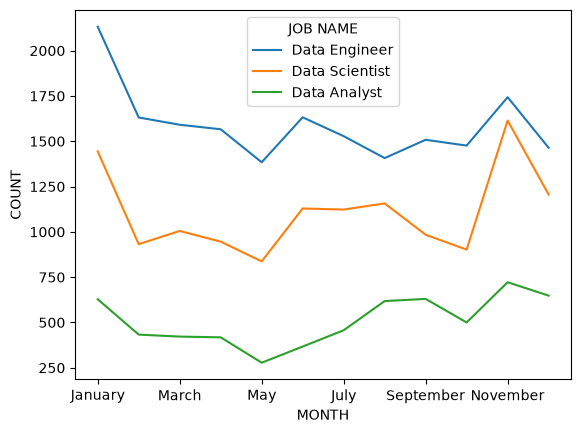

In [19]:
df_top_3.plot(kind='line')
plt.legend(title='JOB NAME')
plt.xlabel('MONTH')
plt.ylabel('COUNT')
plt.show()